## Grafos y comunidades: Análisis

- Se interpretan las comunidades: qué las explica (región, categoría, tipología de KMeans), cómo se relacionan con la centralidad de la Parte IV y dónde hay **grupos cerrados**

- Se responde la parte de PQ2 que toca a los grupos de proveedores que compiten entre sí; local (pandas), salvo las consultas a `participantes` y `hechos`, que van en Spark

### Constantes

- `N_MIN_CERRADO`, `N_CERRADO`: tamaño de un grupo cerrado (3 = el menor grupo con triángulo; 15 = todavía revisable a mano)

- `DENS_MIN`: densidad interna mínima (0.8 = casi todos los pares compiten entre sí)

- `COND_MAX`: conductancia máxima (0.3 = menos de un tercio de su peso sale del grupo)

- `RANGO_DENS`: densidades que se prueban en §7

- `MIN_ADJ`: adjudicaciones mínimas para hablar de concentración en entidades (con menos, el HHI es ruido)

In [1]:
N_MIN_CERRADO, N_CERRADO = 3, 15
DENS_MIN, COND_MAX = 0.8, 0.3
RANGO_DENS = [0.6, 0.7, 0.8, 0.9, 1.0]
MIN_ADJ = 5

### Utilidades

In [2]:
NOTEBOOK = "e_analisis"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

In [4]:
config = leer_config()
n = config["n"]
tabla = lambda nb, t: pd.read_parquet(Path.cwd() / "temp" / nb / "tablas" / t)
v = (pd.read_parquet(datos_dir / "nodos.parquet")
       .merge(pd.read_parquet(datos_dir / "particion.parquet"), on="idx")
       .merge(pd.read_parquet(datos_dir / "bigclam.parquet"), on="idx")
       .merge(pd.read_parquet(datos_dir / "lpa_nucleo.parquet"), on="idx")
       .sort_values("idx", ignore_index=True))
a = pd.read_parquet(datos_dir / "aristas.parquet")
A = matriz(a, n, config["peso"])
memb = pd.read_parquet(datos_dir / "membresias.parquet")
tip = tipologia("proveedor", "proveedor_key").rename(columns={"proveedor_key": "clave"})[["clave", "tipologia"]]
try:
    cen = centralidad_04()
except FileNotFoundError as e:
    print(e); cen = pd.DataFrame(columns=["clave", "pr", "hits", "pct_pr", "pct_hits"])
v = v.merge(tip, on="clave", how="left").merge(cen, on="clave", how="left")
v["tipologia"] = v.tipologia.fillna("sin tipología")
v["c"] = compactar(v[config["principal"]])
hubs = pd.read_parquet(datos_dir / "hubs.parquet").merge(tip, on="clave", how="left").merge(cen, on="clave", how="left")
hubs["tipologia"] = hubs.tipologia.fillna("sin tipología")
assert len(v) == n
print(f"núcleo: {n:,} proveedores, {v.c.nunique()} comunidades ({config['principal']}) | hubs: {len(hubs):,}")

núcleo: 7,114 proveedores, 41 comunidades (louvain) | hubs: 61


---
### **1. ¿Qué explica las comunidades?**

- NMI entre cada partición y cada atributo, contra un **nulo** que permuta el atributo `REPS` veces: un NMI por encima del p95 del nulo no es casualidad

- **Pureza:** fracción de proveedores con el atributo más frecuente de su comunidad

In [5]:
from sklearn.metrics import adjusted_mutual_info_score as ami
SIN_DATO = {"SIN", "sin dato", "sin tipología", "nan", "None"}

particiones = {"louvain": v.louvain.to_numpy(), "espectral": v.espectral.to_numpy(), "lpa (núcleo)": v.lpa.to_numpy(),
               "bigclam (dominante)": v.dominante.to_numpy()}
atributos = ["region_dom", "categoria_dom", "familia_dom", "tipologia", "es_consorcio"]
filas = []
for p, lab in particiones.items():
    for c in atributos:
        y_all = v[c].astype(str)
        for excluye in (False, True):
            ok = v[c].notna().to_numpy() & (lab >= 0)
            if excluye:
                ok &= ~y_all.isin(SIN_DATO).to_numpy()
            x, y = lab[ok], y_all[ok].to_numpy()
            nulo_m, nulo_95 = nmi_nulo(x, y)
            filas.append({"particion": p, "atributo": c, "sin_dato": "excluido" if excluye else "como categoría",
                          "nodos": int(ok.sum()), "categorias": len(np.unique(y)), "nmi": nmi(x, y), "ami": ami(x, y),
                          "nmi_nulo": nulo_m, "nulo_p95": nulo_95, "pureza": pureza(x, y)})
explica = pd.DataFrame(filas)
display(explica.pivot_table(index="atributo", columns=["sin_dato", "particion"], values="ami").round(3))
explica[explica.particion == config["principal"]].round(3)

sin_dato           como categoría                                 \
particion     bigclam (dominante) espectral louvain lpa (núcleo)   
atributo                                                           
categoria_dom               0.238     0.328   0.323        0.226   
es_consorcio                0.000     0.000   0.000       -0.000   
familia_dom                 0.451     0.503   0.500        0.430   
region_dom                  0.231     0.198   0.204        0.249   
tipologia                   0.056     0.075   0.076        0.056   

sin_dato                 excluido                                 
particion     bigclam (dominante) espectral louvain lpa (núcleo)  
atributo                                                          
categoria_dom               0.238     0.328   0.323        0.226  
es_consorcio                0.000     0.000   0.000       -0.000  
familia_dom                 0.503     0.568   0.566        0.499  
region_dom                  0.231     0.198   0.204        0.249  
tipologia                   0.065     0.095   0.095        0.066

,particion,atributo,sin_dato,nodos,categorias,nmi,ami,nmi_nulo,nulo_p95,pureza
0,louvain,region_dom,como categoría,7114,25,0.223,0.204,0.024,0.025,0.562
1,louvain,region_dom,excluido,7114,25,0.223,0.204,0.024,0.025,0.562
2,louvain,categoria_dom,como categoría,7114,3,0.325,0.323,0.003,0.004,0.892
3,louvain,categoria_dom,excluido,7114,3,0.325,0.323,0.003,0.004,0.892
4,louvain,familia_dom,como categoría,5698,213,0.551,0.500,0.103,0.105,0.453
5,louvain,familia_dom,excluido,4594,212,0.618,0.566,0.120,0.123,0.474
6,louvain,tipologia,como categoría,7114,5,0.080,0.076,0.005,0.005,0.489
7,louvain,tipologia,excluido,4311,4,0.100,0.095,0.006,0.007,0.652
8,louvain,es_consorcio,como categoría,7114,2,0.002,0.000,0.002,0.002,0.994
9,louvain,es_consorcio,excluido,7114,2,0.002,0.000,0.002,0.002,0.994


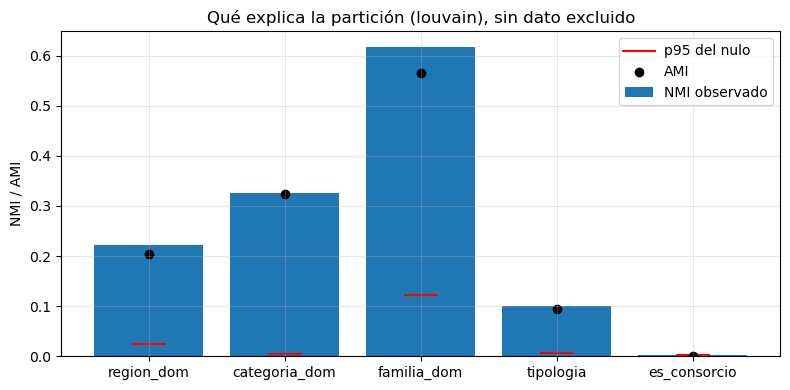

In [6]:
e_ = explica[(explica.particion == config["principal"]) & (explica.sin_dato == "excluido")]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(e_.atributo, e_.nmi, label="NMI observado")
ax.scatter(e_.atributo, e_.nulo_p95, c="red", marker="_", s=600, label="p95 del nulo")
ax.scatter(e_.atributo, e_.ami, c="k", marker="o", label="AMI")
ax.set(ylabel="NMI / AMI", title=f"Qué explica la partición ({config['principal']}), sin dato excluido"); ax.legend()
mostrar_fig("nmi_atributos")

- **El rubro explica más que la región:** familia NMI **0.62** (pureza 47%), categoría **0.33** (pureza **89%**) y región **0.22** (pureza 56%); todas muy sobre el nulo (p95 ≤ 0.12)

- **Se compite por rubro, y dentro del rubro por región:** bienes, servicios y obras casi no se mezclan; la región separa mercados dentro de cada rubro

- **Tipología de KMeans** casi no explica (NMI **0.10**): el perfil (grande, esporádico, sin competencia) no dice con quién se compite; comunidades y clustering miran cosas distintas

- **Consorcio:** NMI ≈ **0**: los consorcios no forman comunidades propias

---
### **2. Perfil de las comunidades**

In [7]:
def moda_pureza(s):
    s = s.dropna().astype(str)
    if s.empty:
        return pd.Series({"valor": "sin dato", "pureza": np.nan})
    vc = s.value_counts()
    return pd.Series({"valor": vc.index[0], "pureza": vc.iloc[0] / len(s)})

perfil = por_comunidad(A, v.c.to_numpy())
for c, nombre in (("region_dom", "region"), ("categoria_dom", "categoria"), ("familia_dom", "familia"), ("tipologia", "tipologia")):
    t = v.groupby("c")[c].apply(moda_pureza).unstack()
    perfil[nombre], perfil[f"pureza_{nombre}"] = t["valor"].to_numpy(), t["pureza"].astype(float).to_numpy()
extra = v.groupby("c").agg(pct_consorcio=("es_consorcio", pct_si), grado_med=("grado_completo", "median"),
                           pct_pr_med=("pct_pr", "median"), pct_hits_med=("pct_hits", "median"))
perfil = perfil.join(extra, on="comunidad")
grandes = perfil[perfil.tamano >= MIN_TAM].sort_values("tamano", ascending=False)
grandes.head(TOP_K).round(3)

,comunidad,tamano,aristas,peso_interno,conductancia,densidad,region,pureza_region,categoria,pureza_categoria,familia,pureza_familia,tipologia,pureza_tipologia,pct_consorcio,grado_med,pct_pr_med,pct_hits_med
0,0,876,4331,13263.314,0.037,0.011,LIMA,0.321,SERVICES,0.901,8110,0.688,sin tipología,0.596,0.457,183.0,0.907,0.683
1,1,560,2015,3982.185,0.099,0.013,LIMA,0.339,WORKS,0.927,7214,0.479,sin tipología,0.684,1.250,249.0,0.878,0.574
2,2,417,1697,3752.974,0.128,0.020,LIMA,0.468,SERVICES,0.918,7214,0.308,sin tipología,0.439,0.240,217.0,0.915,0.875
3,3,416,2757,9491.862,0.023,0.032,LIMA,0.858,SERVICES,0.529,8111,0.231,grandes multicliente,0.394,0.240,183.0,0.949,0.888
4,4,387,1673,3384.864,0.157,0.022,CUSCO,0.395,GOODS,0.713,SIN,0.294,sin tipología,0.390,0.517,217.0,0.923,0.899
5,5,367,2205,8242.335,0.030,0.033,LIMA,0.411,GOODS,0.995,SIN,0.537,grandes multicliente,0.455,0.545,139.0,0.970,0.851
6,6,351,1290,3033.677,0.062,0.021,CUSCO,0.373,SERVICES,0.493,7214,0.347,típicos de pocos clientes,0.570,1.425,159.0,0.913,0.901
7,7,349,2717,15315.443,0.047,0.045,CUSCO,0.530,GOODS,0.963,3011,0.524,típicos de pocos clientes,0.367,0.573,146.0,0.940,0.867
8,8,307,2690,10465.188,0.065,0.057,LIMA,0.932,GOODS,1.000,SIN,0.181,grandes multicliente,0.586,0.326,151.0,0.968,0.991
9,9,298,1394,4531.853,0.195,0.032,LIMA,0.604,GOODS,0.987,SIN,0.273,grandes multicliente,0.416,0.000,156.5,0.946,0.897


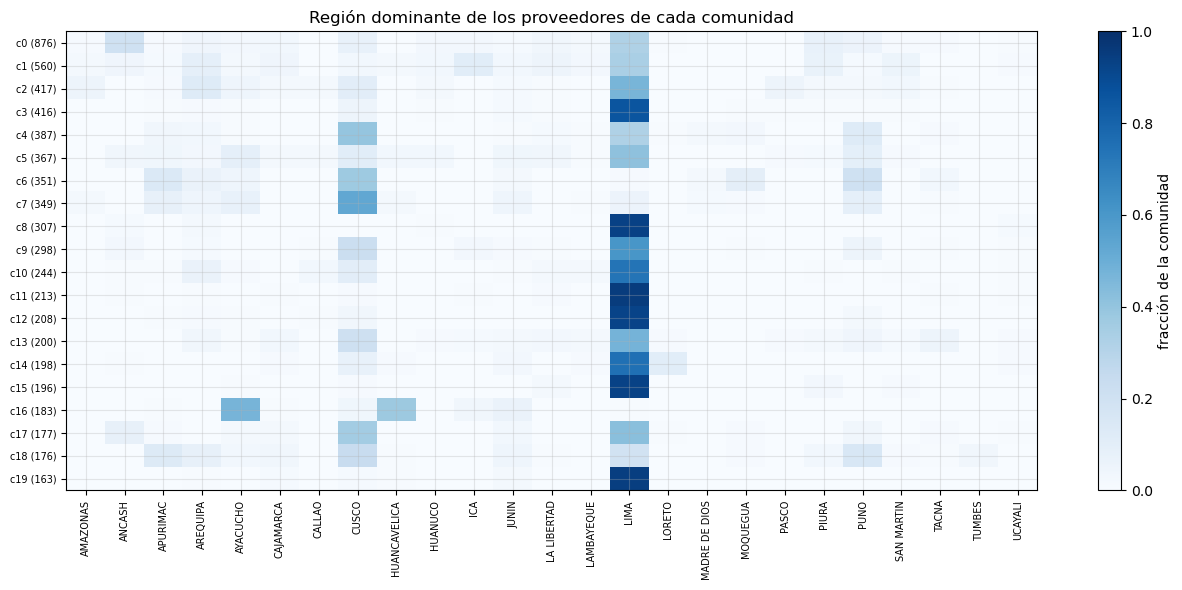

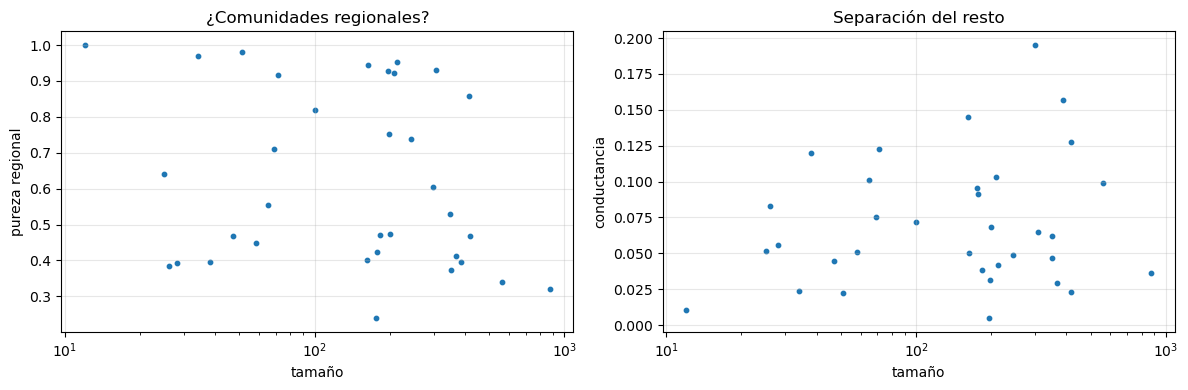

In [8]:
top = grandes.comunidad.head(TOP_K).to_numpy()
sel = v[v.c.isin(top)]
comp = pd.crosstab(sel.c, sel.region_dom, normalize="index").reindex(top)
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(comp.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(comp.shape[1])); ax.set_xticklabels(comp.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(top))); ax.set_yticklabels([f"c{c} ({t})" for c, t in zip(top, grandes.tamano.head(TOP_K))], fontsize=7)
plt.colorbar(im, ax=ax, label="fracción de la comunidad")
ax.set(title="Región dominante de los proveedores de cada comunidad")
mostrar_fig("comunidades_region")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(grandes.tamano, grandes.pureza_region, s=10)
ax[0].set(xscale="log", xlabel="tamaño", ylabel="pureza regional", title="¿Comunidades regionales?")
ax[1].scatter(grandes.tamano, grandes.conductancia, s=10)
ax[1].set(xscale="log", xlabel="tamaño", ylabel="conductancia", title="Separación del resto")
mostrar_fig("perfil_comunidades")

- **34** comunidades con ≥ 10 proveedores reúnen el **99.4%** del núcleo

- **Casi todas son de un solo rubro** (pureza de categoría mediana **0.98**; 28 de 34 sobre 0.9); solo **11 de 34** son regionales (≥ 80% de una región; pureza regional mediana **0.54**)

- **Lima domina** la región de 23 de las 34: las comunidades limeñas se separan por rubro; fuera de Lima aparecen mercados de **Cusco** (7), Cajamarca (2), Ayacucho y Pasco

- **Las más aisladas** (conductancia < 0.03) son mercados de un rubro muy definido: c15 (196 proveedores, familia 9210, 99% de pureza) y c29 (Cajamarca, construcción 7214)

---
### **3. Comunidades y centralidad (Parte IV)**

- Los **hubs** que salieron del núcleo: ¿son los grandes multicliente de PageRank y KMeans?

- Dentro del núcleo, ¿los proveedores centrales del bipartito están concentrados en pocas comunidades o repartidos?

In [9]:
def fila_grupo(d, nombre):
    return {"grupo": nombre, "proveedores": len(d), "grado_med": d.grado.median() if "grado" in d else d.grado_completo.median(),
            "pct_pr_med": d.pct_pr.median(), "pct_hits_med": d.pct_hits.median(),
            "pct_top_pr": 100 * (d.pct_pr >= P_ALTO).mean(), "pct_consorcio": pct_si(d.es_consorcio)}

hubs_vs = pd.DataFrame([fila_grupo(hubs, "hubs (fuera del núcleo)"), fila_grupo(v, "núcleo")])
tip_hubs = (hubs.tipologia.value_counts(normalize=True).rename("hubs").to_frame()
              .join(v.tipologia.value_counts(normalize=True).rename("nucleo"), how="outer").fillna(0))
centrales = v[v.pct_pr >= P_ALTO].c.value_counts()
display(hubs_vs.round(3)); display((100 * tip_hubs).round(1))
print(f"centrales (PageRank ≥ p{P_ALTO * 100:.0f}) en el núcleo: {centrales.sum()} en {len(centrales)} comunidades; "
      f"las 3 con más concentran {centrales.head(3).sum() / max(centrales.sum(), 1):.0%}")

,grupo,proveedores,grado_med,pct_pr_med,pct_hits_med,pct_top_pr,pct_consorcio
0,hubs (fuera del núcleo),61,3571.0,0.955,0.906,14.754,0.000
1,núcleo,7114,157.0,0.933,0.868,9.446,0.576


,hubs,nucleo
tipologia,,
contratistas de obras,6.6,3.7
ganadores sin competencia,0.0,0.1
grandes multicliente,39.3,25.5
sin tipología,34.4,39.4
típicos de pocos clientes,19.7,31.3


centrales (PageRank ≥ p99) en el núcleo: 672 en 33 comunidades; las 3 con más concentran 32%


- **Los hubs son algo más centrales que el núcleo**, no radicalmente: PageRank mediano en percentil **0.96** vs 0.93, y **15%** en el top 1% vs 9%

- **Son más "grandes multicliente"** (39% vs 26%): los que compiten con todos tienden a ser los que venden a muchos, pero un tercio no tiene tipología (no ganan lo suficiente)

- **Dentro del núcleo** los 672 proveedores centrales se reparten en **33** comunidades (las 3 con más reúnen el 32%): cada mercado tiene sus propios proveedores centrales

---
### **4. Grupos cerrados**

- Comunidades chicas (≤ `N_CERRADO`), densas (≥ `DENS_MIN` de los pares compiten entre sí) y aisladas (conductancia ≤ `COND_MAX`): proveedores que **casi solo compiten entre ellos**

- Se buscan en la partición de Louvain con el γ más alto de `b_particion`, porque la modularidad con γ = 1 absorbe los grupos chicos (límite de resolución)

- Para cada grupo se mira en Spark **en qué procesos coinciden** (≥ 2 miembros), cuántos ganadores distintos hay ahí y a qué entidades le venden (`hechos`)

In [10]:
web_g = tabla("b_particion", "particion_gamma_web")
g_fino = web_g.gamma.max()
if g_fino <= config["gamma"]:
    print(f"aviso: el γ más alto disponible ({g_fino}) no es mayor que el de la partición principal ({config['gamma']})")
fino = v.clave.map(web_g[web_g.gamma == g_fino].set_index("clave").comunidad)
assert fino.notna().all(), "hay proveedores sin comunidad en la partición fina"
v["fino"] = compactar(fino.to_numpy())
pf = por_comunidad(A, v.fino.to_numpy())

def cerrados(dens):
    return pf[(pf.tamano >= N_MIN_CERRADO) & (pf.tamano <= N_CERRADO) & (pf.densidad >= dens) & (pf.conductancia <= COND_MAX)]

cand = cerrados(DENS_MIN)
print(f"γ = {g_fino}: {len(pf)} comunidades | grupos cerrados: {len(cand)} con {cand.tamano.sum()} proveedores")

γ = 10.0: 142 comunidades | grupos cerrados: 11 con 38 proveedores


In [11]:
moda_txt = lambda s: s.mode().iat[0] if s.notna().any() else "sin dato"
if cand.empty:
    print("Sin grupos cerrados con estos umbrales: ver la variación de DENS_MIN en §7")
    grupos = pd.DataFrame(columns=["grupo", "tamano", "region", "procesos_juntos", "ganadores_distintos", "hhi_entidades"])
else:
    miembros = v[v.fino.isin(cand.comunidad)][["clave", "fino", "nombre", "es_consorcio", "region_dom", "categoria_dom"]]
    m_s = spark.createDataFrame(miembros[["clave", "fino"]].rename(columns={"clave": "proveedor_key", "fino": "grupo"}))
    part = leer(final_dir, "participantes").select("ocid", "proveedor_key", F.col("gano").cast("int").alias("gano"))
    juntos = (part.join(F.broadcast(m_s), "proveedor_key")
                  .withColumn("k", F.count("*").over(Window.partitionBy("ocid", "grupo"))).where("k >= 2"))
    proc_g = (juntos.groupBy("grupo").agg(F.countDistinct("ocid").alias("procesos_juntos"), F.sum("gano").alias("victorias_juntos"),
                                          F.countDistinct(F.when(F.col("gano") == 1, F.col("proveedor_key"))).alias("ganadores_distintos"))
                    .toPandas())
    adj = (leer(final_dir, "hechos").select("entidad_key", "proveedor_key", "monto_asignado").join(F.broadcast(m_s), "proveedor_key")
             .groupBy("grupo", "entidad_key").agg(F.count("*").alias("n"), F.sum("monto_asignado").alias("monto")).toPandas())
    conc = adj.groupby("grupo").apply(lambda d: pd.Series({
        "entidades": len(d), "adjudicaciones": d.n.sum(), "monto": d.monto.sum(),
        "cuota_entidad_top": d.n.max() / d.n.sum(), "hhi_entidades": ((d.n / d.n.sum()) ** 2).sum()}))
    nombres = miembros.groupby("fino").agg(miembros=("nombre", lambda s: " | ".join(s.astype(str).str[:40])),
                                           pct_consorcio=("es_consorcio", pct_si), region=("region_dom", moda_txt),
                                           categoria=("categoria_dom", moda_txt))
    grupos = (cand.set_index("comunidad").join(nombres).join(proc_g.set_index("grupo")).join(conc)
                  .rename_axis("grupo").reset_index())
    hechos = leer(final_dir, "hechos")
    if "ocid" in hechos.columns:                        # concentración solo en los procesos conjuntos
        proc_j = juntos.select("ocid", "grupo").distinct()
        adj_j = (hechos.select("ocid", "entidad_key", "proveedor_key").join(F.broadcast(m_s), "proveedor_key")
                       .join(proc_j, ["ocid", "grupo"]).groupBy("grupo", "entidad_key").count().toPandas())
        grupos = grupos.merge(adj_j.groupby("grupo")["count"]
                                   .agg(adj_juntos="sum", hhi_juntos=lambda s: ((s / s.sum()) ** 2).sum())
                                   .reset_index(), on="grupo", how="left")
    grupos["tasa_victoria_juntos"] = grupos.victorias_juntos / grupos.procesos_juntos
    grupos["cautivo"] = ((grupos.hhi_entidades >= UMBRAL_HHI) & (grupos.adjudicaciones >= MIN_ADJ)).astype(int)
    grupos["triangulo"] = (grupos.tamano == 3).astype(int)
    grupos["patron"] = np.select(
        [grupos.tasa_victoria_juntos < 0.05,
         (grupos.ganadores_distintos >= 2) & (grupos.tasa_victoria_juntos >= 0.2)],
        ["coinciden y casi no ganan", "varios miembros ganan"], "mixto")
grupos.sort_values("procesos_juntos", ascending=False).round(3)

,grupo,tamano,aristas,peso_interno,conductancia,densidad,miembros,pct_consorcio,region,categoria,...,adjudicaciones,monto,cuota_entidad_top,hhi_entidades,adj_juntos,hhi_juntos,tasa_victoria_juntos,cautivo,triangulo,patron
0,112,7,19,33.677,0.184,0.905,CORPORACION SAGITARIO E.H. S.A.C | DANILKA CONSULTORIA Y CONSTRUCCION S.A.C...,0.0,LIMA,SERVICES,...,37.0,35080695.58,0.189,0.085,33,0.096,0.088,0,0,mixto
6,130,3,3,15.228,0.114,1.000,TOPASA INGENIEROS E.I.R.L. | ARGOS CORPORATION S.A.C. | CORPORACION KATSUMOT...,0.0,LIMA,WORKS,...,2.0,1067575.60,1.000,1.000,1,1.000,0.005,0,1,coinciden y casi no ganan
10,134,3,3,6.137,0.081,1.000,BUTRON QUISPE PAOLA FILOMENA | AJOSA INGENIERIA SOCIEDAD ANONIMA CERRAD | GR...,0.0,PUNO,GOODS,...,37.0,5585708.11,0.189,0.088,18,0.204,0.145,0,1,mixto
5,129,3,3,11.930,0.137,1.000,VARGAS VALVERDE JUAN EPIFANIO | HUARHUA YPARRAGUIRRE LUIS MODESTO | DISCONSU...,0.0,LIMA,SERVICES,...,1.0,59250.00,1.000,1.000,1,1.000,0.008,0,1,coinciden y casi no ganan
7,131,3,3,9.583,0.280,1.000,SERVICIOS Y MATERIALES ELECTRICOS EMPRES | PRYSTEL S.A.C | CONECTATE SERV...,0.0,CUSCO,GOODS,...,29.0,9039026.43,0.103,0.063,19,0.086,0.200,0,1,varios miembros ganan
4,128,3,3,6.216,0.101,1.000,26 RED S.A.C. | GRUPO CORPORATIVO D'LIMA S.A.C. | WJM S.A.C.,0.0,CALLAO,GOODS,...,4.0,1871660.00,0.500,0.375,3,0.556,0.034,0,1,coinciden y casi no ganan
1,123,4,6,9.167,0.055,1.000,CONSTRUCTORA E INGENIERIA Y EJECUTORES G | JOALSA CONSTRUCTORA E.I.R.L. | CO...,0.0,LIMA,WORKS,...,8.0,3181977.35,0.250,0.188,3,0.556,0.034,0,0,coinciden y casi no ganan
9,133,3,3,10.273,0.148,1.000,CORPORACION ALIMENTARIA LA FAVORITA E.I. | INCACORP PERU S.R.L. | THM SOLUCI...,0.0,PUNO,GOODS,...,8.0,1975448.84,0.375,0.219,7,0.265,0.108,0,1,mixto
8,132,3,3,5.159,0.209,1.000,FIBERSIDE TECHNOLOGIES S.A.C. | TAHUA TECNOLOGIES S.A.C. | AMPER SISTEMAS SU...,0.0,LIMA,GOODS,...,9.0,44955302.66,0.333,0.185,4,0.375,0.069,0,1,mixto
2,126,3,3,13.881,0.238,1.000,PONTIFICIA UNIVERSIDAD CATOLICA DEL PERU | UNIVERSIDAD SAN IGNACIO DE LOYOLA...,0.0,LIMA,SERVICES,...,75.0,32638729.23,0.173,0.079,24,0.253,0.421,0,1,varios miembros ganan


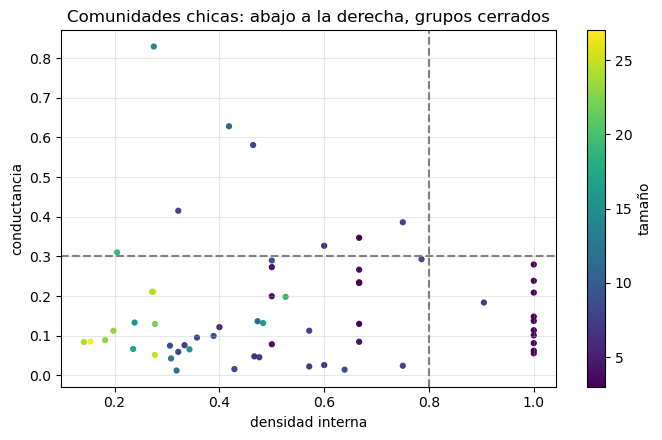

In [12]:
ch = pf[(pf.tamano >= N_MIN_CERRADO) & (pf.tamano <= 2 * N_CERRADO)]
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(ch.densidad, ch.conductancia, c=ch.tamano, s=12, cmap="viridis")
ax.axvline(DENS_MIN, ls="--", c="gray"); ax.axhline(COND_MAX, ls="--", c="gray")
plt.colorbar(sc, ax=ax, label="tamaño")
ax.set(xlabel="densidad interna", ylabel="conductancia", title="Comunidades chicas: abajo a la derecha, grupos cerrados")
mostrar_fig("grupos_cerrados")

- **11 grupos cerrados** (**38** proveedores; 10 son tríos o cuartetos) que coinciden en **89** procesos en mediana (de 32 a 373)

- **3** de ellos venden casi solo a una entidad (HHI ≥ 0.25); dos tríos coinciden en **121** y **208** procesos, ganan solo **1** y esa adjudicación es con una sola entidad

- **4 grupos "coinciden y casi no ganan"** (victoria conjunta < 5%): se presentan juntos de forma sistemática sin llevarse el proceso

- **Lectura:** es compatible con mercados locales chicos (pocos proveedores habilitados) y también con acuerdos de reparto o de acompañamiento; **la red no distingue entre ambos** (§9)

---
### **5. Solapamiento por comunidad (BigCLAM)**

In [13]:
mm = memb.merge(v[["idx", "c", "region_dom", "n_comunidades"]], on="idx")
perfil_bc = mm.groupby("comunidad").agg(
    tamano=("idx", "size"), pct_solapados=("n_comunidades", lambda s: 100 * (s >= 2).mean()),
    comunidad_principal=("c", lambda s: s.mode().iat[0]), cuota_principal=("c", lambda s: s.value_counts(normalize=True).iat[0]),
    region=("region_dom", moda_txt),
    pureza_region=("region_dom", lambda s: s.value_counts(normalize=True).iat[0] if s.notna().any() else np.nan))
estado = np.select([v.n_comunidades >= 2, v.n_comunidades == 1], ["solapado", "una"], "ninguna")
tip_sol = pd.crosstab(v.tipologia, estado, normalize="columns").reindex(columns=["ninguna", "una", "solapado"],
                                                                        fill_value=0)
residual = v.n_comunidades >= 10
print(f"solapados: {(v.n_comunidades >= 2).sum()} proveedores | en 2–5 comunidades: {v.n_comunidades.between(2, 5).sum()} | "
      f"en ≥ 10 (hubs residuales): {residual.sum()}, grado mediano {v.grado_completo[residual].median():.0f} vs {v.grado_completo.median():.0f} del núcleo")
display(perfil_bc.sort_values("tamano", ascending=False).head(TOP_K).round(3)); display((100 * tip_sol).round(1))

solapados: 711 proveedores | en 2–5 comunidades: 644 | en ≥ 10 (hubs residuales): 57, grado mediano 1303 vs 157 del núcleo


,tamano,pct_solapados,comunidad_principal,cuota_principal,region,pureza_region
comunidad,,,,,,
71,800,6.875,0,0.846,LIMA,0.328
55,567,41.270,7,0.563,CUSCO,0.490
65,430,12.326,5,0.735,LIMA,0.530
74,402,38.060,13,0.483,LIMA,0.530
50,400,41.500,10,0.565,LIMA,0.668
52,382,30.105,8,0.660,LIMA,0.919
81,337,26.706,3,0.804,LIMA,0.935
78,334,41.317,12,0.452,LIMA,0.853
53,252,44.048,20,0.516,CUSCO,0.484


col_0,ninguna,una,solapado
tipologia,,,
contratistas de obras,7.0,2.5,2.0
ganadores sin competencia,0.1,0.1,0.1
grandes multicliente,14.6,27.4,44.4
sin tipología,48.6,37.1,27.7
típicos de pocos clientes,29.6,33.0,25.7


- **Las 20 comunidades más grandes de BigCLAM** caen en su mayoría dentro de una comunidad de Louvain (cuota 0.31–0.94); la mediana sobre las 100 baja a **0.30**, arrastrada por los hubs residuales

- **Puentes típicos:** **644** proveedores en 2–5 comunidades, sobre todo **grandes multicliente** (44% de los solapados vs 27% de los de una comunidad)

- **Hubs residuales:** **57** proveedores aparecen en ≥ 10 comunidades (grado mediano **1,303** vs 157); quedaron bajo el umbral de hub (2,554) pero BigCLAM los trata como hubs

---
### **6. Acuerdo entre métodos**

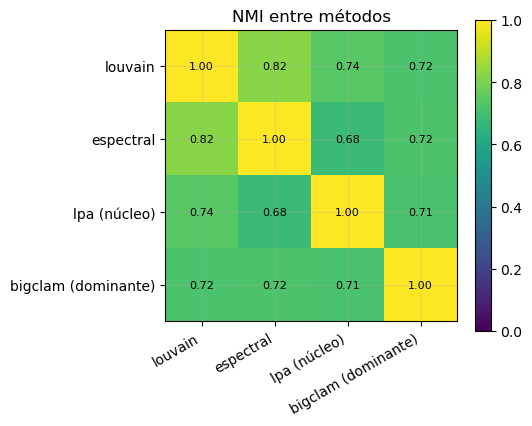

,a,b,nodos,nmi,ari
0,louvain,espectral,7114,0.821,0.703
1,louvain,lpa (núcleo),7114,0.741,0.410
2,louvain,bigclam (dominante),7114,0.718,0.557
3,espectral,lpa (núcleo),7114,0.683,0.326
4,espectral,bigclam (dominante),7114,0.719,0.593
5,lpa (núcleo),bigclam (dominante),7114,0.712,0.367


In [14]:
def par(x, y, f):
    ok = (x >= 0) & (y >= 0)
    return f(x[ok], y[ok]), int(ok.sum())

nombres_p = list(particiones)
acuerdo = pd.DataFrame([{"a": x, "b": y, "nodos": par(particiones[x], particiones[y], nmi)[1],
                         "nmi": par(particiones[x], particiones[y], nmi)[0],
                         "ari": par(particiones[x], particiones[y], ari)[0]}
                        for k_, x in enumerate(nombres_p) for y in nombres_p[k_ + 1:]])
mat = np.eye(len(nombres_p))
for r in acuerdo.itertuples():
    i_, j_ = nombres_p.index(r.a), nombres_p.index(r.b)
    mat[i_, j_] = mat[j_, i_] = r.nmi
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(mat, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(nombres_p))); ax.set_xticklabels(nombres_p, rotation=30, ha="right")
ax.set_yticks(range(len(nombres_p))); ax.set_yticklabels(nombres_p)
for i_ in range(len(nombres_p)):
    for j_ in range(len(nombres_p)):
        ax.text(j_, i_, f"{mat[i_, j_]:.2f}", ha="center", va="center", color="w" if mat[i_, j_] < .6 else "k", fontsize=8)
plt.colorbar(im, ax=ax); ax.set_title("NMI entre métodos")
mostrar_fig("acuerdo_metodos")
acuerdo.round(3)

- **Louvain y espectral** son los más parecidos (NMI **0.82**); BigCLAM dominante queda a 0.71–0.72 de todos

- **LPA es el que más se aparta** (NMI 0.68–0.74, ARI 0.33–0.41): fragmenta en muchas comunidades chicas

- Las conclusiones de §1–§4 se sostienen con Louvain, espectral y BigCLAM; LPA solo como aproximación

---
### **7. Variación de los resultados**

In [15]:
b_n = tabla("a_grafo", "barrido_nucleo")
lvg = tabla("b_particion", "louvain_gamma")
sd = tabla("c_solapadas", "eleccion_delta")
filas_extra = []
pb_ = datos_dir / "particion_barrido.parquet"
if pb_.exists():
    pb = pd.read_parquet(pb_)
    base = pd.Series(np.asarray(louvain(a_networkx(A), 1.0)), index=v.clave)      # γ = 1, igual que en a_grafo
    for (mc, tp), d in pb.groupby(["min_cop", "tope"]):
        com = d[d.clave.isin(base.index)]
        filas_extra.append({"parametro": "núcleo: NMI vs núcleo elegido (γ = 1)", "valor": f"{mc}, {tp}",
                            "resultado": f"NMI {nmi(base.loc[com.clave].to_numpy(), com.comunidad.to_numpy()):.2f} "
                                         f"en {len(com):,} nodos comunes"})
persist = {d: set(cerrados(d).comunidad) for d in RANGO_DENS}
en_todos = sorted(set.intersection(*persist.values()))
filas_extra.append({"parametro": "grupos cerrados presentes en todos los umbrales", "valor": "",
                    "resultado": ", ".join(map(str, en_todos)) or "ninguno"})

variacion = pd.concat([
    b_n[b_n.viable].assign(parametro="núcleo (min_cop, tope)", valor=lambda t: t.min_cop.astype(str) + ", " + t.tope.astype(str),
                           resultado=lambda t: t.nodos.astype(str) + " nodos, " + t.pct_peso.round(1).astype(str) + "% del peso"),
    lvg.assign(parametro="γ de Louvain", valor=lambda t: t.gamma.astype(str),
               resultado=lambda t: "Q " + t.Q.round(3).astype(str) + ", " + t.comunidades.astype(int).astype(str)
                                   + " comunidades, estabilidad " + t.estabilidad.round(2).astype(str)),
    sd.assign(parametro="δ de BigCLAM", valor=lambda t: t.delta.round(4).astype(str),
              resultado=lambda t: "cobertura " + (100 * t.cobertura).round(1).astype(str) + "%, solapados "
                                  + t.pct_solapados.round(1).astype(str) + "%"),
    pd.DataFrame([{"parametro": "densidad mínima de un grupo cerrado", "valor": str(d), "resultado": f"{len(cerrados(d))} grupos"}
                  for d in RANGO_DENS]), pd.DataFrame(filas_extra)])[["parametro", "valor", "resultado"]]
variacion

,parametro,valor,resultado
7,"núcleo (min_cop, tope)","20, sin tope","7937 nodos, 32.0% del peso"
15,"núcleo (min_cop, tope)","20, 0.999","7114 nodos, 22.0% del peso"
22,"núcleo (min_cop, tope)","15, 0.99","7084 nodos, 12.5% del peso"
23,"núcleo (min_cop, tope)","20, 0.99","4059 nodos, 9.3% del peso"
29,"núcleo (min_cop, tope)","10, 0.95","3772 nodos, 3.6% del peso"
0,γ de Louvain,0.25,"Q 0.838, 15 comunidades, estabilidad 0.87"
1,γ de Louvain,0.5,"Q 0.864, 24 comunidades, estabilidad 0.91"
2,γ de Louvain,0.75,"Q 0.868, 32 comunidades, estabilidad 0.94"
3,γ de Louvain,1.0,"Q 0.869, 36 comunidades, estabilidad 0.94"
4,γ de Louvain,1.25,"Q 0.868, 40 comunidades, estabilidad 0.95"


- **Núcleo:** con otros filtros viables el núcleo cambia de tamaño (3,772–7,937 nodos), pero las comunidades de los nodos comunes se parecen (NMI **0.76–0.86**)

- **γ:** entre **0.5** y **2** la Q varía menos de **0.006** y la estabilidad se mantiene ≥ 0.91

- **Grupos cerrados:** su número depende de la densidad exigida (**20** con 0.6, **10** con 1.0), pero **10 de los 11** aparecen en todos los umbrales

---
### **8. Casos concretos**

In [16]:
mayor = grandes.iloc[0]
base_pura = grandes[grandes.tamano >= 5 * MIN_TAM] if (grandes.tamano >= 5 * MIN_TAM).any() else grandes
pura = base_pura[base_pura.region != "LIMA"].sort_values("pureza_region", ascending=False).iloc[0]
aislada = grandes.sort_values("conductancia").iloc[0]
hub = hubs.sort_values("grado", ascending=False).iloc[0]
filas = [
    {"caso": "comunidad más grande", "detalle": f"c{mayor.comunidad}: {mayor.tamano} proveedores, {mayor.region} ({mayor.pureza_region:.0%}), {mayor.categoria}"},
    {"caso": "comunidad más regional (fuera de Lima)", "detalle": f"c{pura.comunidad}: {pura.tamano} proveedores, {pura.pureza_region:.0%} de {pura.region}"},
    {"caso": "comunidad más aislada", "detalle": f"c{aislada.comunidad}: {aislada.tamano} proveedores, conductancia {aislada.conductancia:.2f}, {aislada.region}"},
    {"caso": "hub de mayor grado", "detalle": f"{hub.nombre}: grado {hub.grado}, {hub.tipologia}"}]

if v.n_comunidades.between(2, 5).any():                # puente típico: pocas comunidades, no un hub residual
    puente = v[v.n_comunidades.between(2, 5)].sort_values(["n_comunidades", "grado_completo"], ascending=False).iloc[0]
    filas.append({"caso": "proveedor puente (BigCLAM)",
                  "detalle": f"{puente.nombre}: {puente.n_comunidades} comunidades, grado {puente.grado_completo}"})
if len(grupos):
    g0 = grupos.sort_values("procesos_juntos", ascending=False).iloc[0]
    filas.append({"caso": "grupo cerrado con más coincidencias",
                  "detalle": f"{g0.tamano} proveedores ({g0.region}), {g0.procesos_juntos:.0f} procesos juntos, "
                             f"{g0.ganadores_distintos:.0f} ganadores distintos, HHI entidades {g0.hhi_entidades:.2f}"})
casos = pd.DataFrame(filas)
casos

,caso,detalle
0,comunidad más grande,"c0: 876 proveedores, LIMA (32%), SERVICES"
1,comunidad más regional (fuera de Lima),"c7: 349 proveedores, 53% de CUSCO"
2,comunidad más aislada,"c15: 196 proveedores, conductancia 0.00, LIMA"
3,hub de mayor grado,"TVT QONTRATISTAS E.I.R.L.: grado 12059, grandes multicliente"
4,proveedor puente (BigCLAM),"GRUPO HEICI S.A.C: 5 comunidades, grado 2399"
5,grupo cerrado con más coincidencias,"7 proveedores (LIMA), 373 procesos juntos, 6 ganadores distintos, HHI entida..."


- **c0** (comunidad más grande): 876 proveedores de servicios (90%), principalmente de ingeniería (familia 8110); solo 32% de Lima: un mercado nacional por rubro

- **c7** (más regional fuera de Lima): 349 proveedores de bienes, 53% de Cusco: mercado regional de un rubro

- **Proveedor puente** (BigCLAM): en 5 comunidades con grado 2,399, justo bajo el umbral de hub; participa en varios mercados sin ser de los 61 retirados

- **Grupo cerrado con más coincidencias:** 7 proveedores de servicios en Lima, 373 procesos juntos y 6 ganadores distintos (HHI 0.09): compiten de verdad entre ellos y venden a muchas entidades

---
### **9. Limitaciones y ética**

- **Co-participación no es colusión:** coincidir muchas veces describe un mercado chico o especializado tanto como un acuerdo; un grupo cerrado es una señal para revisar, no una acusación

- **El núcleo excluye a los hubs** y a las coincidencias esporádicas: las comunidades describen el mercado "medio", no a los proveedores nacionales

- **Consorcios sin miembros:** la fuente no publica quién los integra; un grupo empresarial repartido en varios consorcios puede verse como un grupo cerrado (o como nodos separados)

- **Región del proveedor inferida** de sus procesos, no de su domicilio

- **Las comunidades dependen de γ, k y δ:** por eso se publican con la variación (§7) y con sliders en el reporte

- **Uso responsable:** los grupos con nombres se publican como **perfiles para revisión** por los órganos de control, con la metodología al lado, nunca como lista de sospechosos

---
### **10. Síntesis**

- **Grafo:** co-participación con peso Σ 1/(n − 1); los 61 hubs (grado ≥ **2,554**) y las coincidencias de < 20 procesos se retiran para formar un núcleo de **7,114** proveedores

- **Partición:** Louvain (γ = **1.25**, Q **0.870**) supera al espectral (Q **0.843**) y reproduce a Girvan–Newman en la muestra (NMI 0.90); Girvan–Newman no escala ni con betweenness aproximado

- **Solapadas:** BigCLAM (K = **100**, AUC **0.971**) coincide con Louvain a nivel de nodo (NMI 0.72) y detecta **10%** de proveedores en varios mercados

- **Escalabilidad:** LPA en Spark (igual al local, ARI 1.0) corre sobre el grafo completo; sin hubs da Q **0.680**

- **PQ2:** los mercados se organizan **por rubro** (bienes, servicios y obras casi no se mezclan) y, dentro del rubro, por región; los proveedores centrales de la Parte IV están repartidos en casi todas las comunidades; hay **11 grupos cerrados**, **3** con ventas concentradas en una entidad, como casos a revisar

---
### **11. Escritura de resultados**

- `comunidades_web_nodos` / `comunidades_web_aristas`: grafo de comunidades (las 50 más grandes, posiciones con *spring layout*) para el reporte

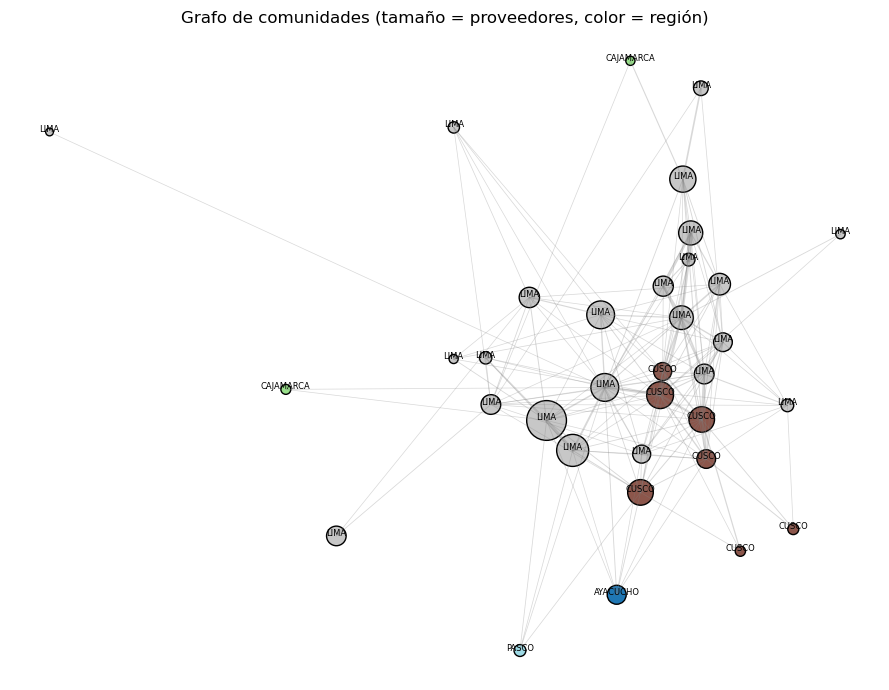

In [17]:
H = indicadora(v.c.to_numpy())
W = (H.T @ A @ H).tocoo()
sel_c = set(grandes.comunidad.head(50))
meta_a = pd.DataFrame({"c1": W.row, "c2": W.col, "peso": W.data})
meta_a = meta_a[(meta_a.c1 < meta_a.c2) & meta_a.c1.isin(sel_c) & meta_a.c2.isin(sel_c)]
Gm = nx.Graph(); Gm.add_nodes_from(sel_c); Gm.add_weighted_edges_from(meta_a.itertuples(index=False))
xy = nx.spring_layout(Gm, weight="weight", seed=SEED)
meta_n = (grandes[grandes.comunidad.isin(sel_c)][["comunidad", "tamano", "region", "pureza_region", "categoria", "conductancia"]]
            .assign(x=lambda t: t.comunidad.map(lambda c: xy[c][0]), y=lambda t: t.comunidad.map(lambda c: xy[c][1])))

fig, ax = plt.subplots(figsize=(9, 7))
for r in meta_a.itertuples():
    ax.plot([xy[r.c1][0], xy[r.c2][0]], [xy[r.c1][1], xy[r.c2][1]], c="gray", alpha=.3, lw=.5 + 3 * r.peso / meta_a.peso.max())
ax.scatter(meta_n.x, meta_n.y, s=20 + 800 * meta_n.tamano / meta_n.tamano.max(),
           c=meta_n.region.astype("category").cat.codes, cmap="tab20", edgecolors="k")
for r in meta_n.itertuples():
    ax.text(r.x, r.y, str(r.region)[:10], fontsize=6, ha="center")
ax.set(title="Grafo de comunidades (tamaño = proveedores, color = región)"); ax.axis("off")
mostrar_fig("grafo_comunidades")

In [18]:
nodos_web = v[["clave", "nombre", "c", "fino", "n_comunidades", "region_dom", "categoria_dom", "tipologia", "pct_pr", "grado_completo"]]
escritos = guardar_tablas({"explica": explica, "perfil_comunidades": grandes, "hubs_vs_nucleo": hubs_vs,
                           "tipologia_hubs": tip_hubs.rename_axis("tipologia").reset_index(), "grupos_cerrados": grupos,
                           "perfil_bigclam": perfil_bc.reset_index(),
                           "tipologia_solapados": tip_sol.rename_axis("tipologia").reset_index(),
                           "acuerdo_metodos": acuerdo, "variacion": variacion, "casos": casos,
                           "comunidades_web_nodos": meta_n, "comunidades_web_aristas": meta_a, "nodos_web": nodos_web})

Escrito en 05_Comunidad/temp/e_analisis/: explica, perfil_comunidades, hubs_vs_nucleo, tipologia_hubs, grupos_cerrados, perfil_bigclam, tipologia_solapados, acuerdo_metodos, variacion, casos, comunidades_web_nodos, comunidades_web_aristas, nodos_web


#### a. Verificación

In [19]:
verificar_salidas(escritos)
assert (explica.nmi >= 0).all() and (explica.nmi <= 1 + 1e-9).all(), "NMI fuera de [0, 1]"
assert grandes.tamano.sum() <= n and (v.c >= 0).all(), "hay proveedores sin comunidad"
print("NMI en [0, 1] | todos los proveedores tienen comunidad")

OK: 13 tablas (parquet + json) | 6 figuras: acuerdo_metodos, comunidades_region, grafo_comunidades, grupos_cerrados, nmi_atributos, perfil_comunidades
NMI en [0, 1] | todos los proveedores tienen comunidad


---
### **12. Cerrar sesión**

In [20]:
spark.stop()